# 02 EDA
Summarize target balance, numeric distributions, and categorical churn rates.

In [8]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_raw_data
from src.eda import numeric_summary, categorical_churn_rates

data = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
 ]
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Churn rate: 26.537%
Retention rate: 73.463%
Imbalance ratio (retained/churned): 2.77


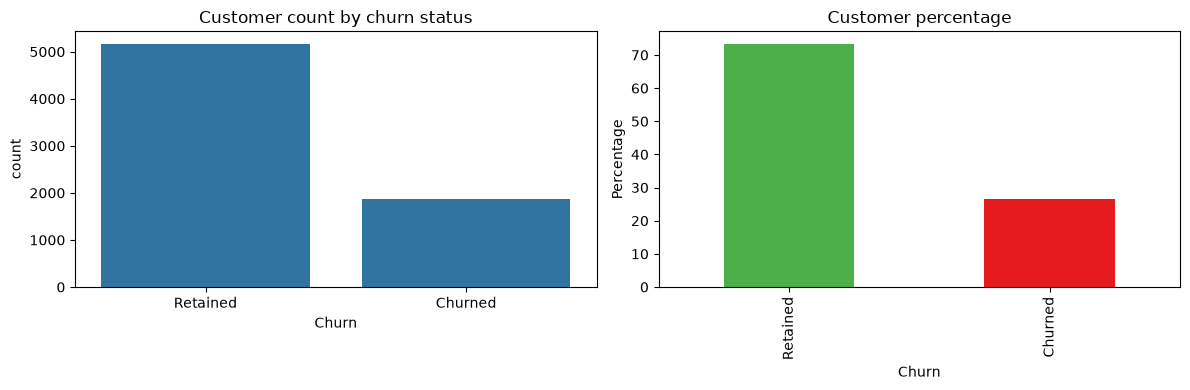

,customer_count,percentage
Churn,,
Retained,5174,73.463013
Churned,1869,26.536987


In [9]:
target_summary = data["Churn"].value_counts().sort_index().rename(index={0: "Retained", 1: "Churned"}).to_frame("customer_count")
target_summary["percentage"] = target_summary["customer_count"] / len(data) * 100
churn_rate = float(data["Churn"].mean())
retention_rate = 1.0 - churn_rate
class_counts = data["Churn"].value_counts()
imbalance_ratio = float(class_counts[0] / class_counts[1])
print(f"Churn rate: {churn_rate:.3%}")
print(f"Retention rate: {retention_rate:.3%}")
print(f"Imbalance ratio (retained/churned): {imbalance_ratio:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x="Churn", order=[0, 1], ax=axes[0])
axes[0].set_title("Customer count by churn status")
axes[0].set_xticks([0, 1], ["Retained", "Churned"])
target_summary["percentage"].plot.bar(ax=axes[1], color=["#4daf4a", "#e41a1c"], title="Customer percentage")
axes[1].set_ylabel("Percentage")
plt.tight_layout()
plt.show()
target_summary

In [10]:
# Numerical descriptive statistics required by the project brief.
numeric_stats = numeric_summary(data, numeric_columns)
numeric_stats

,count,mean,std,min,25%,50%,75%,max,variance,skewness,kurtosis,iqr
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,6.031681e+02,0.239540,-1.387372,46.0000
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,9.054109e+02,-0.220524,-1.257260,54.3500
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,5.138252e+06,0.961642,-0.231799,3393.2875


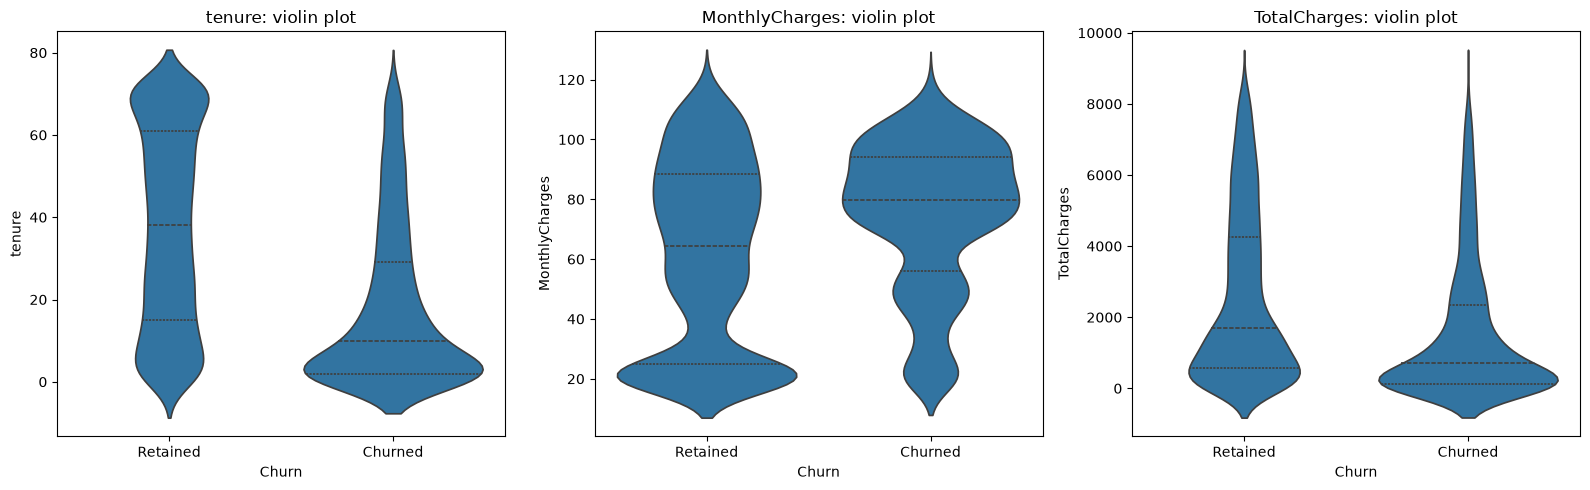

In [12]:
# Violin plots show distribution shape and density by churn status.
fig, axes = plt.subplots(1, len(numeric_columns), figsize=(16, 5))
for axis, column in zip(axes, numeric_columns):
    sns.violinplot(data=data, x="Churn", y=column, order=[0, 1], inner="quartile", ax=axis)
    axis.set_title(f"{column}: violin plot")
    axis.set_xticks([0, 1], ["Retained", "Churned"] )
plt.tight_layout()
plt.show()

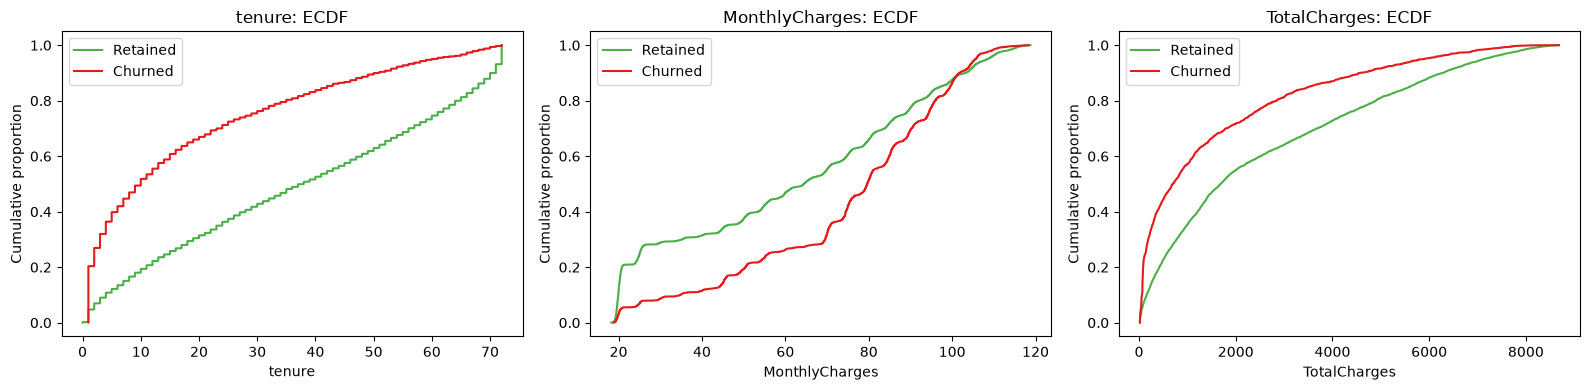

In [13]:
# ECDF comparison makes distribution shifts visible without binning choices.
def ecdf(values):
    sorted_values = values.dropna().sort_values().to_numpy()
    probabilities = (sorted_values.argsort().argsort() + 1) / len(sorted_values)
    return sorted_values, probabilities

fig, axes = plt.subplots(1, len(numeric_columns), figsize=(16, 4))
for axis, column in zip(axes, numeric_columns):
    for churn_value, label, color in [(0, "Retained", "#4daf4a"), (1, "Churned", "#e41a1c")]:
        values, probabilities = ecdf(data.loc[data["Churn"] == churn_value, column])
        axis.plot(values, probabilities, label=label, color=color)
    axis.set_title(f"{column}: ECDF")
    axis.set_xlabel(column)
    axis.set_ylabel("Cumulative proportion")
    axis.legend()
plt.tight_layout()
plt.show()


gender


,gender,customer_count,churn_rate,churn_rate_pct
0,Female,3488,0.269209,26.920872
1,Male,3555,0.261603,26.160338



SeniorCitizen


,SeniorCitizen,customer_count,churn_rate,churn_rate_pct
0,0,5901,0.236062,23.606168
1,1,1142,0.416813,41.681261



Partner


...

,Contract,customer_count,churn_rate,churn_rate_pct
0,Month-to-month,3875,0.427097,42.709677
1,One year,1473,0.112695,11.269518
2,Two year,1695,0.028319,2.831858



PaperlessBilling


,PaperlessBilling,customer_count,churn_rate,churn_rate_pct
0,No,2872,0.163301,16.330084
1,Yes,4171,0.335651,33.565092



PaymentMethod


,PaymentMethod,customer_count,churn_rate,churn_rate_pct
0,Bank transfer (automatic),1544,0.167098,16.709845
1,Credit card (automatic),1522,0.152431,15.243101
2,Electronic check,2365,0.452854,45.285412
3,Mailed check,1612,0.191067,19.1067


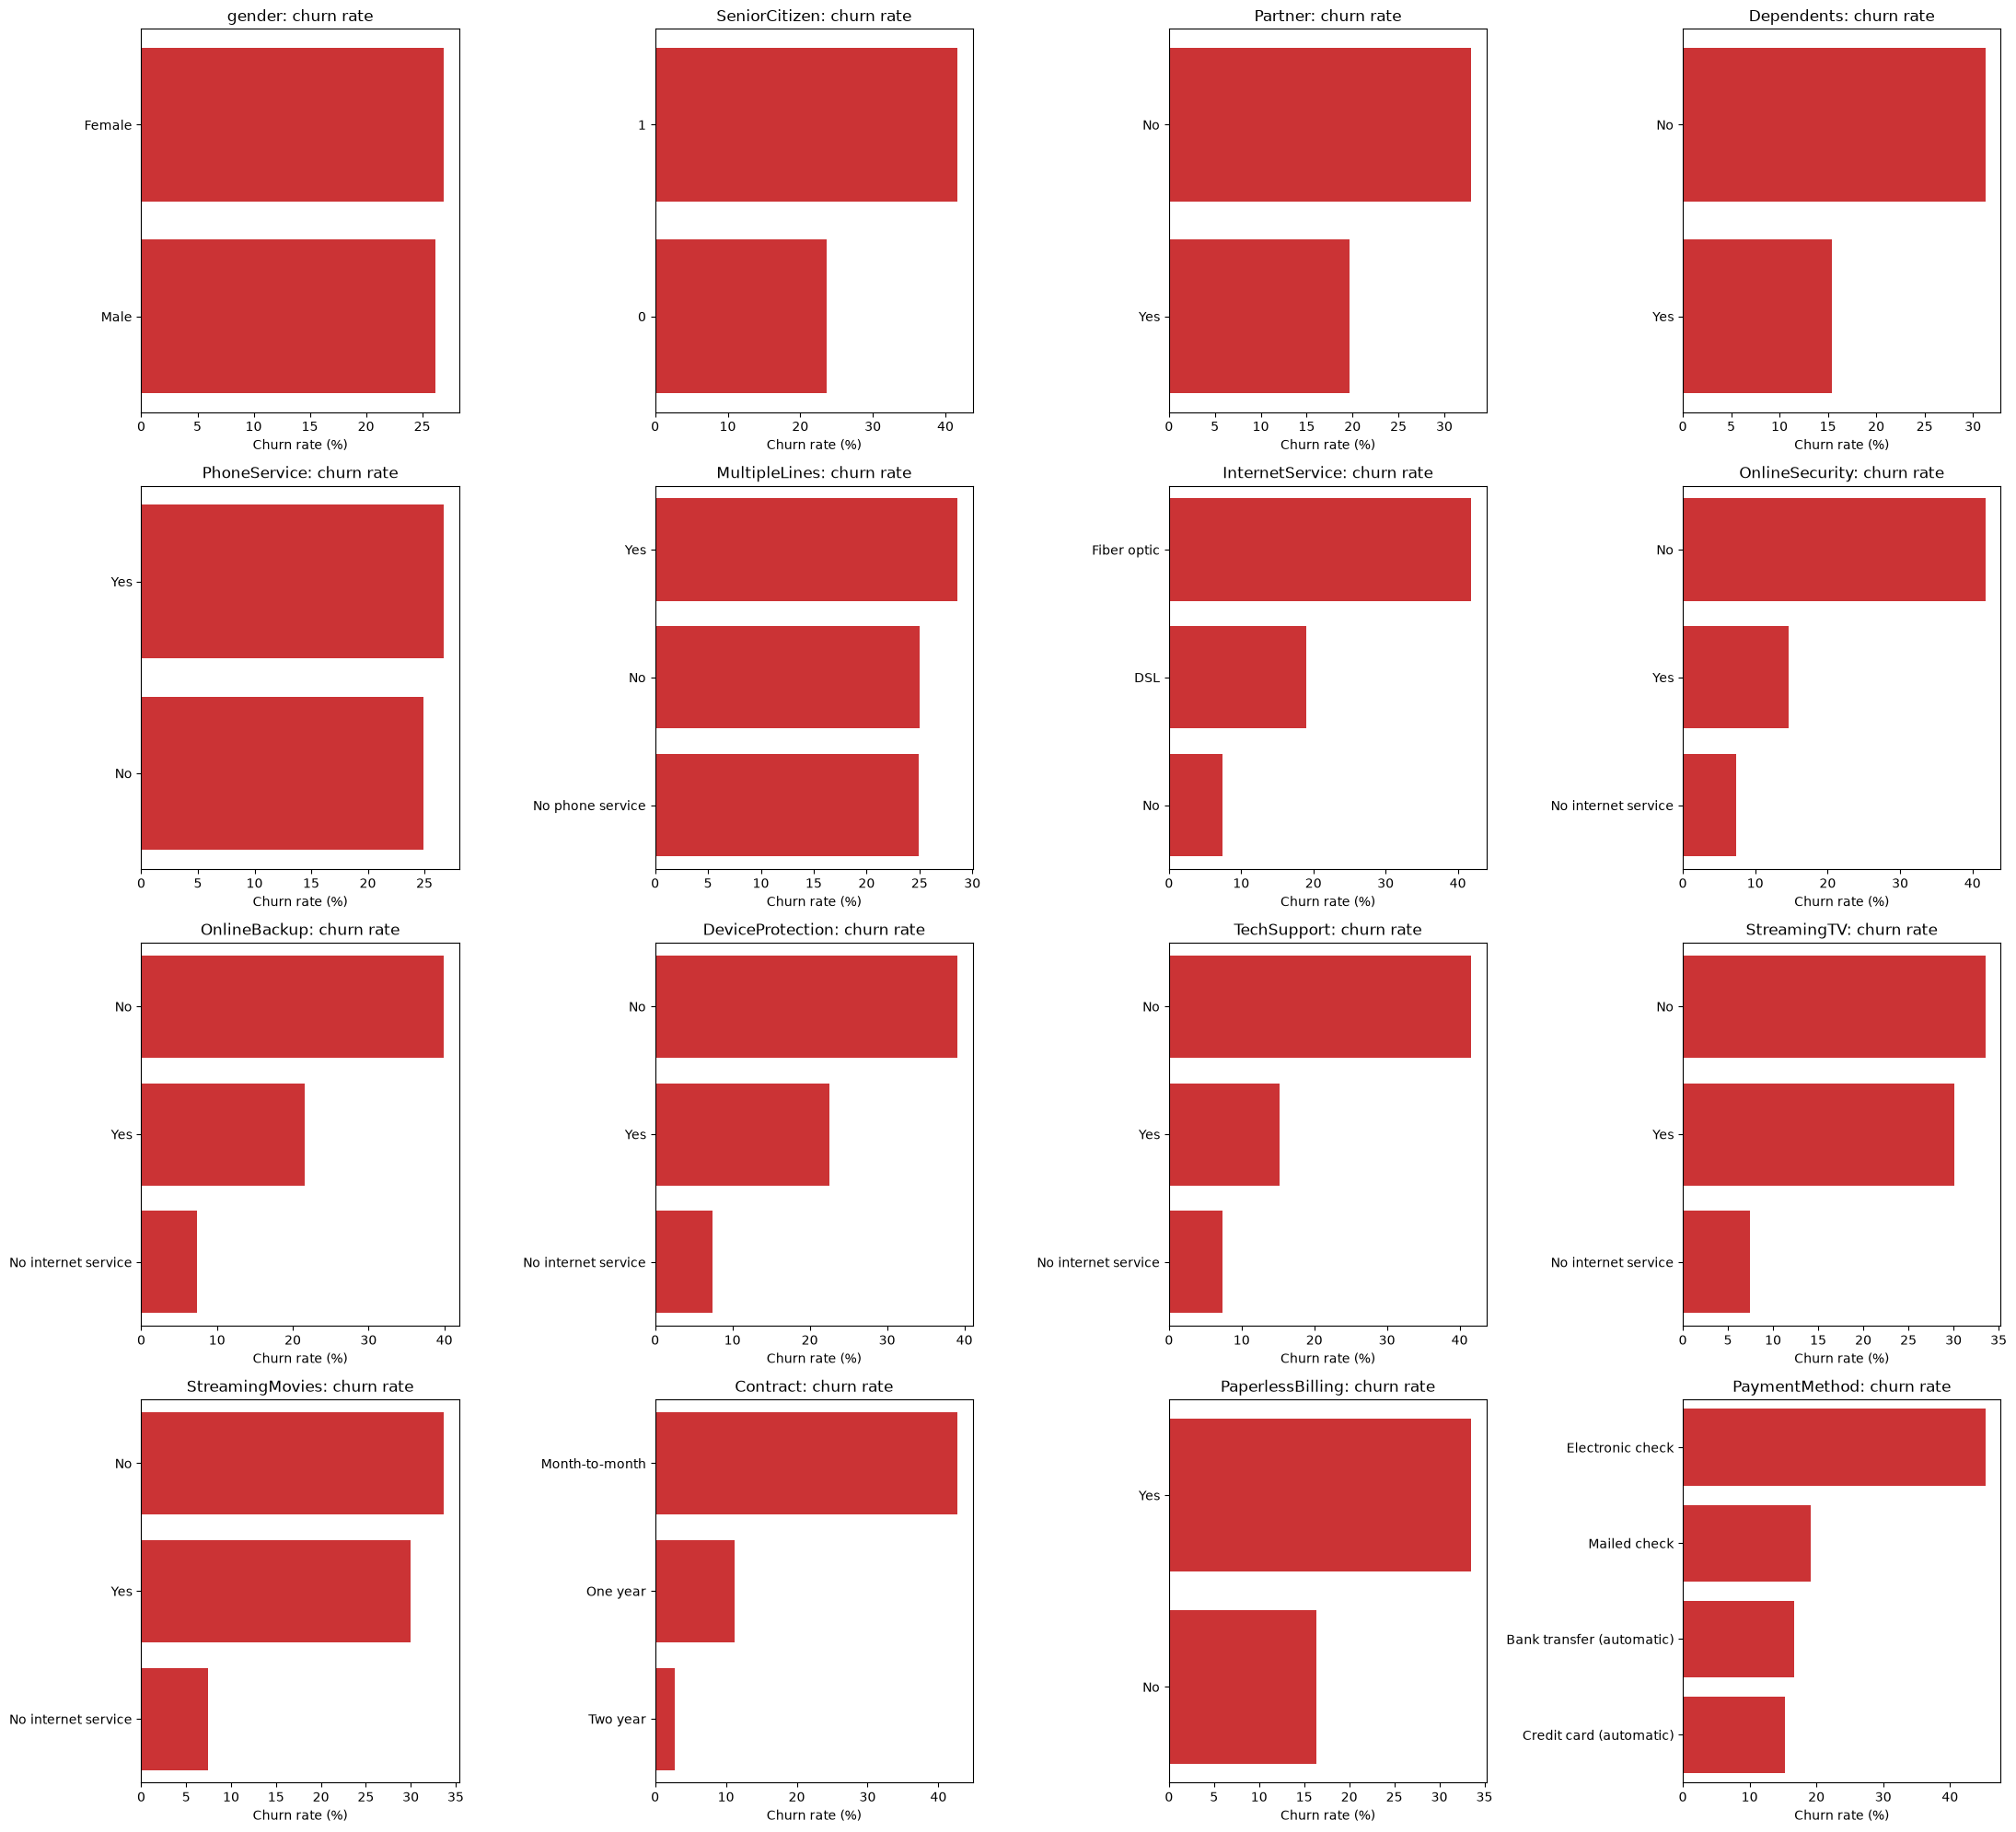

In [14]:
# Every categorical result reports customer count separately from churn rate.
categorical_tables = {}
for column in categorical_columns:
    table = categorical_churn_rates(data, [column], target="Churn")
    table["churn_rate_pct"] = table["churn_rate"] * 100
    categorical_tables[column] = table.sort_values("churn_rate", ascending=False)
    print(f"\n{column}")
    display(table.sort_values(column).reset_index(drop=True))

# Churn-rate plots answer risk questions; count plots answer volume questions.
plot_rows = []
for column, table in categorical_tables.items():
    current = table.copy()
    current["category"] = current[column].astype(str)
    current["feature"] = column
    plot_rows.append(current[["feature", "category", "customer_count", "churn_rate_pct"]])
categorical_plot_data = pd.concat(plot_rows, ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(22, 20))
for axis, column in zip(axes.flat, categorical_columns):
    current = categorical_plot_data[categorical_plot_data["feature"] == column].sort_values("churn_rate_pct", ascending=False)
    sns.barplot(data=current, x="churn_rate_pct", y="category", color="#e41a1c", ax=axis)
    axis.set_title(f"{column}: churn rate")
    axis.set_xlabel("Churn rate (%)")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

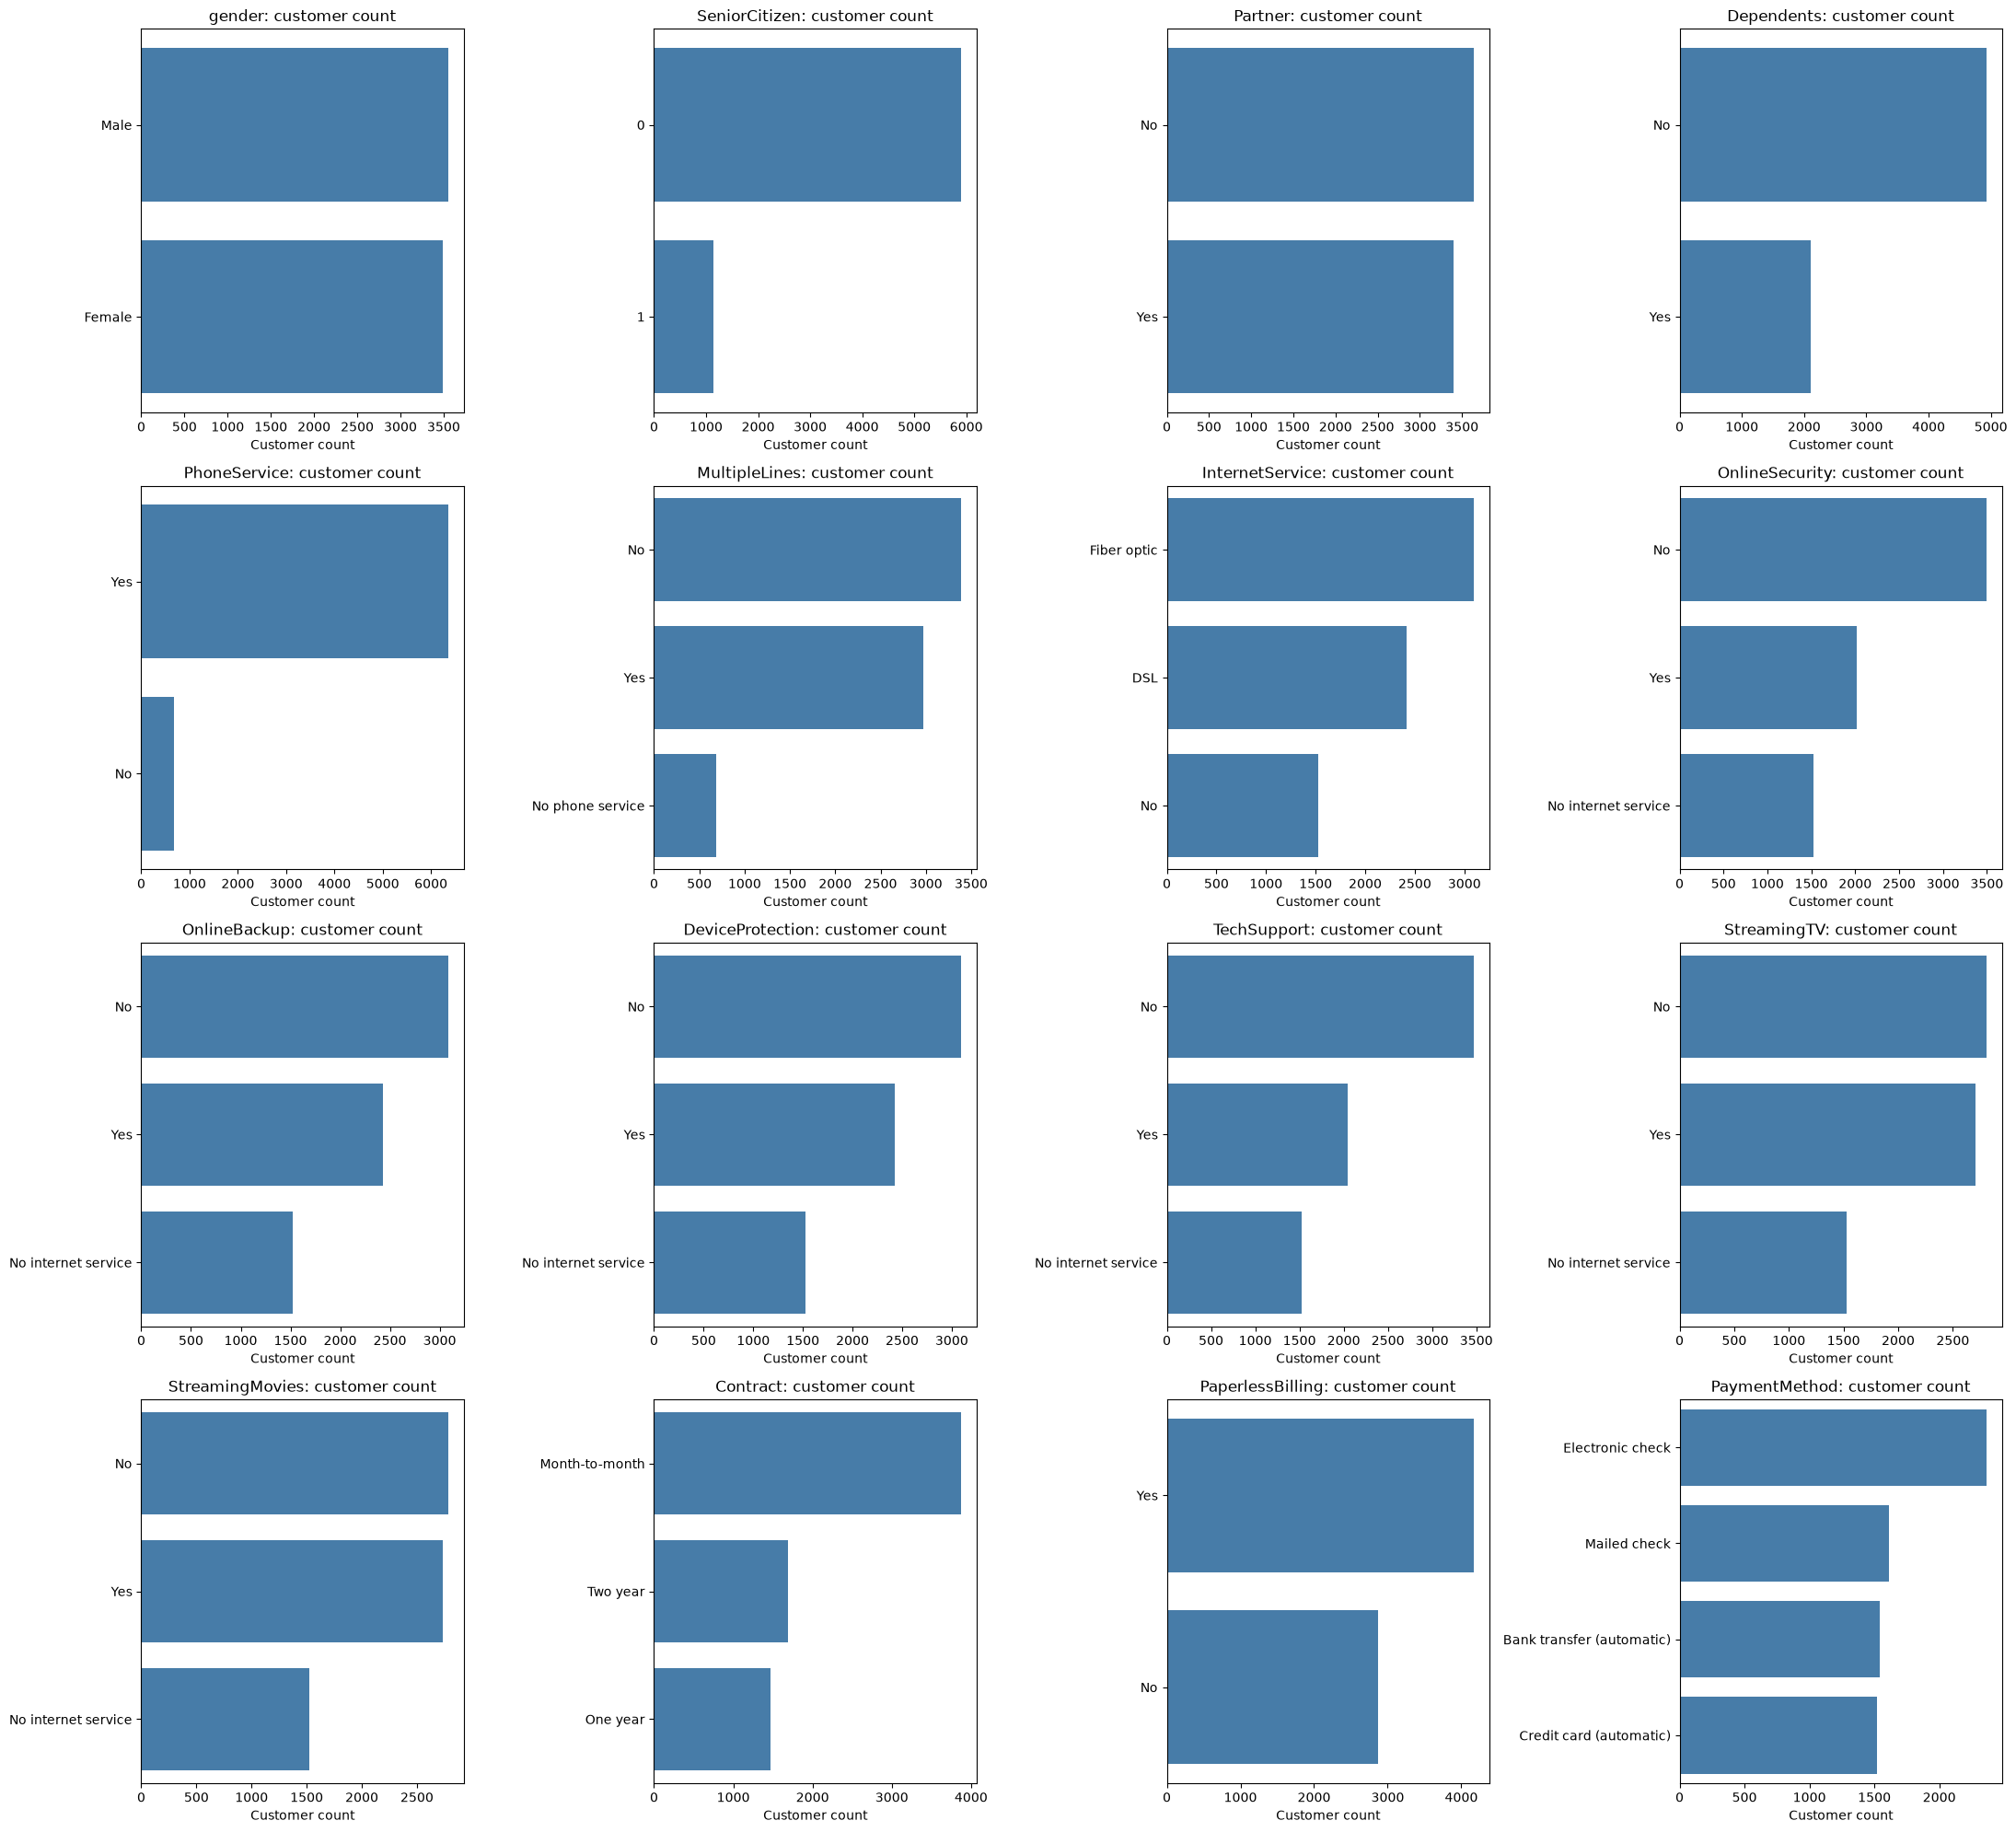

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(22, 20))
for axis, column in zip(axes.flat, categorical_columns):
    current = categorical_plot_data[categorical_plot_data["feature"] == column].sort_values("customer_count", ascending=False)
    sns.barplot(data=current, x="customer_count", y="category", color="#377eb8", ax=axis)
    axis.set_title(f"{column}: customer count")
    axis.set_xlabel("Customer count")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

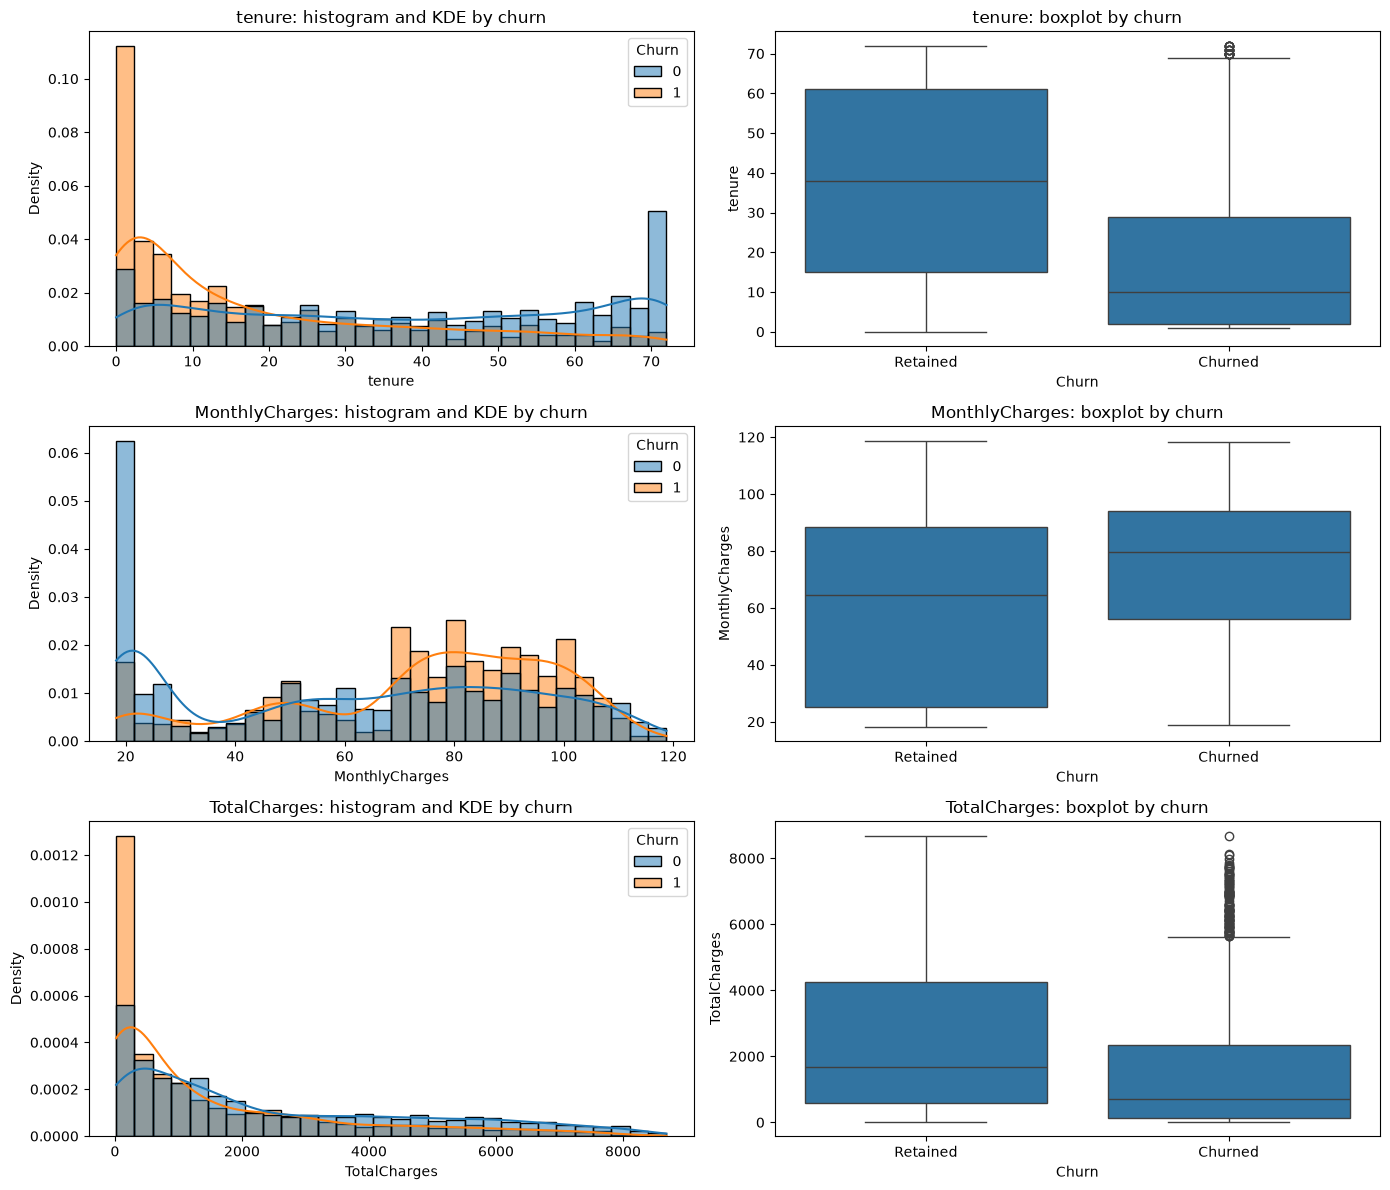

In [11]:
# Histograms and KDEs compare the distributions of retained and churned customers.
fig, axes = plt.subplots(len(numeric_columns), 2, figsize=(14, 12))
for row, column in enumerate(numeric_columns):
    sns.histplot(data=data, x=column, hue="Churn", bins=30, kde=True, stat="density", common_norm=False, ax=axes[row, 0])
    axes[row, 0].set_title(f"{column}: histogram and KDE by churn")
    sns.boxplot(data=data, x="Churn", y=column, order=[0, 1], ax=axes[row, 1])
    axes[row, 1].set_title(f"{column}: boxplot by churn")
    axes[row, 1].set_xticks([0, 1], ["Retained", "Churned"] )
plt.tight_layout()
plt.show()

In [16]:
# Univariate analysis: inspect one variable at a time before studying relationships.
univariate_numeric = data[numeric_columns].describe().T
univariate_numeric["missing"] = data[numeric_columns].isna().sum()
univariate_numeric["unique_values"] = data[numeric_columns].nunique(dropna=True)
univariate_numeric

,count,mean,std,min,25%,50%,75%,max,missing,unique_values
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0,73
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,0,1585
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,11,6530


In [17]:
# Bivariate analysis: compare each numerical feature with churn.
bivariate_numeric = data.groupby("Churn")[numeric_columns].agg(["count", "mean", "median"]).round(3)
bivariate_numeric

tenure                MonthlyCharges                 TotalCharges  \
       count    mean median          count    mean  median        count   
Churn                                                                     
0       5174  37.570   38.0           5174  61.265  64.425         5163   
1       1869  17.979   10.0           1869  74.441  79.650         1869   

                          
           mean   median  
Churn                     
0      2555.344  1683.60  
1      1531.796   703.55

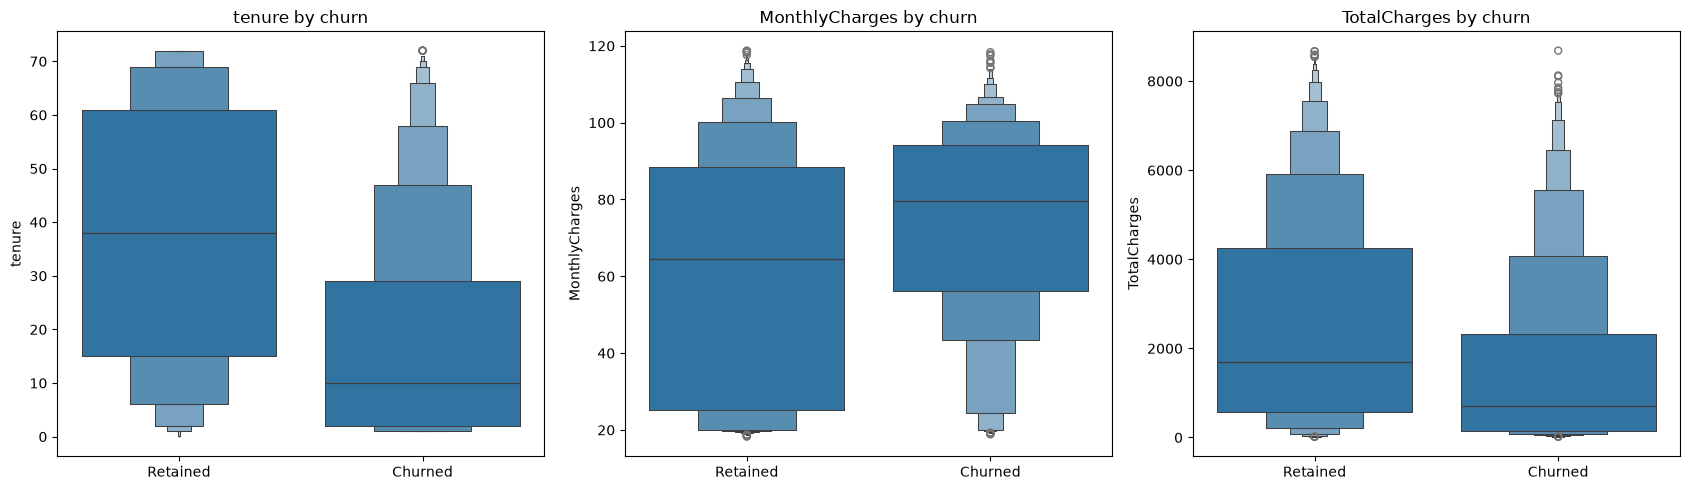

In [18]:
# Bivariate visualizations: numerical features versus the binary target.
fig, axes = plt.subplots(1, len(numeric_columns), figsize=(17, 5))
for axis, column in zip(axes, numeric_columns):
    sns.boxenplot(data=data, x="Churn", y=column, order=[0, 1], ax=axis)
    axis.set_title(f"{column} by churn")
    axis.set_xticks([0, 1], ["Retained", "Churned"] )
    axis.set_xlabel("")
plt.tight_layout()
plt.show()

In [19]:
# Bivariate categorical analysis: cross-tabulations retain both volume and risk.
selected_categorical = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
categorical_bivariate = {}
for column in selected_categorical:
    categorical_bivariate[column] = categorical_churn_rates(data, [column], target="Churn").sort_values("churn_rate", ascending=False)
categorical_bivariate

{'Contract':          Contract  customer_count  churn_rate
 0  Month-to-month            3875    0.427097
 1        One year            1473    0.112695
 2        Two year            1695    0.028319,
 'InternetService':   InternetService  customer_count  churn_rate
 1     Fiber optic            3096    0.418928
 0             DSL            2421    0.189591
 2              No            1526     0.07405,
 'PaymentMethod':                PaymentMethod  customer_count  churn_rate
 2           Electronic check            2365    0.452854
 3               Mailed check            1612    0.191067
 0  Bank transfer (automatic)            1544    0.167098
 1    Credit card (automatic)            1522    0.152431,
 'TechSupport':            TechSupport  customer_count  churn_rate
 0                   No            3473    0.416355
 2                  Yes            2044    0.151663
 1  No internet service            1526     0.07405}

In [ ]:
# Multivariate analysis: inspect interactions among important categorical variables.
interaction_table = data.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc=["mean", "count"]).round(3)
interaction_table

In [ ]:
# Multivariate interaction heatmap: each cell contains the observed churn rate.
contract_internet_rate = data.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean")
contract_internet_count = data.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="size")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(contract_internet_rate, annot=True, fmt=".1%", cmap="Reds", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Churn rate: Contract x InternetService")
sns.heatmap(contract_internet_count, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Customer count: Contract x InternetService")
plt.tight_layout()
plt.show()

In [ ]:
# Multivariate numeric view: pairwise relationships split by churn status.
pairplot_columns = ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
pairplot_data = data[pairplot_columns].copy()
sns.pairplot(pairplot_data, vars=numeric_columns, hue="Churn", diag_kind="kde", corner=True, plot_kws={"alpha": 0.35, "s": 18})
plt.show()

In [ ]:
# Step 1: define the numeric predictors for collinearity diagnostics.
# Churn is the target, not a predictor; it is shown separately only for association analysis.
correlation_columns = ["SeniorCitizen"] + numeric_columns
numeric_for_collinearity = data[correlation_columns].copy()
numeric_for_collinearity["TotalCharges"] = numeric_for_collinearity["TotalCharges"].fillna(numeric_for_collinearity["TotalCharges"].median())
numeric_for_collinearity.head()

In [ ]:
# Step 2: correlation matrix. Pearson measures linear association; Spearman measures monotonic association.
pearson_matrix = numeric_for_collinearity.corr(method="pearson")
spearman_matrix = numeric_for_collinearity.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson correlation: numeric predictors")
sns.heatmap(spearman_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation: numeric predictors")
plt.tight_layout()
plt.show()
pearson_matrix

In [ ]:
# Step 3: list unique predictor pairs with strong absolute correlation.
# This is a screening diagnostic, not an automatic feature-deletion rule.
correlation_threshold = 0.70
strong_pairs = []
for left_index, left_column in enumerate(correlation_columns):
    for right_column in correlation_columns[left_index + 1:]:
        pearson_value = pearson_matrix.loc[left_column, right_column]
        spearman_value = spearman_matrix.loc[left_column, right_column]
        if max(abs(pearson_value), abs(spearman_value)) >= correlation_threshold:
            strong_pairs.append({"feature_1": left_column, "feature_2": right_column, "pearson": pearson_value, "spearman": spearman_value})
strong_correlation_pairs = pd.DataFrame(strong_pairs).sort_values("pearson", key=lambda values: values.abs(), ascending=False) if strong_pairs else pd.DataFrame(columns=["feature_1", "feature_2", "pearson", "spearman"])
strong_correlation_pairs

In [ ]:
# Step 4: calculate VIF for each numeric predictor.
# VIF quantifies how much a feature is explained by the other predictors.
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_table = pd.DataFrame({"feature": correlation_columns})
vif_table["vif"] = [variance_inflation_factor(numeric_for_collinearity.to_numpy(), index) for index in range(numeric_for_collinearity.shape[1])]
vif_table["interpretation"] = pd.cut(vif_table["vif"], bins=[-float("inf"), 5, 10, float("inf")], labels=["Usually acceptable", "Review possible redundancy", "High multicollinearity; investigate"])
vif_table.sort_values("vif", ascending=False)

## Collinearity interpretation
1. Correlation describes pairwise association; it does not prove causation.
2. Pearson is sensitive to linear association, while Spearman captures monotonic rank association.
3. A strong predictor-predictor correlation can indicate redundant information, but tree models may still use both features.
4. VIF considers all other numeric predictors together; it is a diagnostic, not an automatic deletion rule.
5. Feature removal should be considered only with business meaning, validation performance, stability, and interpretability.
6. The target `Churn` is excluded from VIF because target association is not predictor multicollinearity.

## Outcome and usefulness

### Outcome
- The dataset contains 7,043 customers: 5,174 retained and 1,869 churned.
- The observed churn rate is 26.537%, the retention rate is 73.463%, and the retained-to-churned imbalance ratio is approximately 2.77.
- Numerical EDA covers `tenure`, `MonthlyCharges`, and `TotalCharges` with descriptive statistics, histograms, KDEs, boxplots, violin plots, ECDFs, and churn-group comparisons.
- The numerical distributions differ between retained and churned customers. In particular, churn is concentrated more heavily among shorter-tenure customers and customers with higher monthly charges.
- Categorical analysis reports customer count separately from churn rate. This distinction prevents a large category from being mistaken for the riskiest category merely because it contains more customers.
- The categorical tables and plots identify business segments whose observed churn rates differ, including contract, internet service, support, payment, billing, and household-profile categories.
- The correlation and VIF section assesses redundancy among numeric predictors. Correlation and VIF are diagnostics; neither is an automatic deletion rule for the tree-based models.

### Why this is useful
- It establishes class imbalance before selecting metrics. Accuracy alone would be insufficient because the retained class is much larger.
- It shows which variables deserve deeper statistical investigation and which segments may be useful for business recommendations.
- It reveals shape, skewness, outliers, thresholds, and distribution shifts that a single average would hide.
- It separates customer volume from customer risk, which is essential when prioritizing retention campaigns.
- It highlights possible redundancy before feature selection and helps interpret why engineered variables may overlap with raw variables.
- It provides the visual evidence needed to formulate testable hypotheses without claiming that an observed pattern is causal.

### Modeling hand-off
Use PR-AUC, ROC-AUC, recall, precision, F1, calibration, and business-cost analysis rather than accuracy alone. Carry the strongest patterns into statistical testing, linearity/nonlinearity diagnostics, and validation-only feature selection.